Tugas Machine Learning 8

8.1 Persiapan Library

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, \
    GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, \
    accuracy_score

8.2 Import Dataset

In [ ]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y,
    test_size=0.2, random_state=42, stratify=y)

8.3 Preprocessing

In [ ]:
pipeline = Pipeline([("scaler", StandardScaler()), ("svm",
    SVC())])

8.4 Training Model dengan GridSearchCV

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
])

param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [0.001, 0.01, 0.1, 1],
    "svm__kernel": ["rbf", "linear"]
}

grid_search = GridSearchCV(
    pipeline, param_grid, cv=5, scoring="f1", n_jobs=-1
)
grid_search.fit(X_train, y_train)

print("Parameter terbaik:", grid_search.best_params_)
print("F1-Score terbaik (CV):", round(grid_search.best_score_, 3))

Parameter terbaik: {'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
F1-Score terbaik (CV): 0.984


8.5 Evaluasi

In [ ]:
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
print("Akurasi Test:", round(accuracy_score(y_test, y_pred),
    3))
print(classification_report(y_test, y_pred))

Akurasi Test: 0.982
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



8.6 Visualisasi

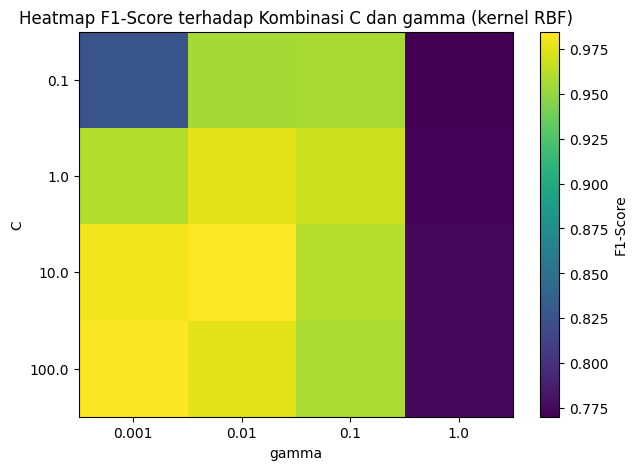

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

hasil = pd.DataFrame(grid_search.cv_results_)

hasil = hasil[hasil["param_svm__kernel"] == "rbf"]

pivot = hasil.pivot_table(
    values="mean_test_score",
    index="param_svm__C",
    columns="param_svm__gamma"
)

plt.figure(figsize=(7, 5))
plt.imshow(pivot, cmap="viridis", aspect="auto")
plt.xticks(range(len(pivot.columns)), pivot.columns)
plt.yticks(range(len(pivot.index)), pivot.index)
plt.xlabel("gamma"); plt.ylabel("C")
plt.title("Heatmap F1-Score terhadap Kombinasi C dan gamma "
          "(kernel RBF)")
plt.colorbar(label="F1-Score")
plt.show()

8.7 Praktikum 1


=== Praktikum 1: Perbandingan Kernel ===
Kernel    Akurasi  F1 test        F1 CV (5-fold)
linear      0.974    0.979         0.974 +/- 0.011
poly        0.912    0.935         0.924 +/- 0.012
rbf         0.982    0.986         0.977 +/- 0.014


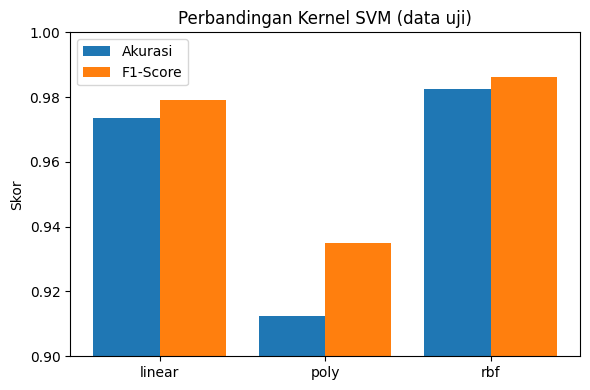

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score
from sklearn.inspection import DecisionBoundaryDisplay

data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y,
    test_size=0.2, random_state=42, stratify=y)


print("\n=== Praktikum 1: Perbandingan Kernel ===")
print(f"{'Kernel':<8}{'Akurasi':>9}{'F1 test':>9}{'F1 CV (5-fold)':>22}")
nama_kernel, acc_list, f1_list = [], [], []
for kernel in ["linear", "poly", "rbf"]:
    model = Pipeline([("scaler", StandardScaler()),
                      ("svm", SVC(kernel=kernel))])
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    cv = cross_val_score(model, X_train, y_train, cv=5, scoring="f1")
    nama_kernel.append(kernel)
    acc_list.append(acc)
    f1_list.append(f1)
    print(f"{kernel:<8}{acc:>9.3f}{f1:>9.3f}"
          f"{cv.mean():>14.3f} +/- {cv.std():.3f}")

x = np.arange(len(nama_kernel))
plt.figure(figsize=(6, 4))
plt.bar(x - 0.2, acc_list, width=0.4, label="Akurasi")
plt.bar(x + 0.2, f1_list, width=0.4, label="F1-Score")
plt.xticks(x, nama_kernel)
plt.ylim(0.9, 1.0)
plt.ylabel("Skor")
plt.title("Perbandingan Kernel SVM (data uji)")
plt.legend()
plt.tight_layout()
plt.savefig("perbandingan_kernel.png", dpi=120)
plt.show()

8.7 Praktikum 2


=== Praktikum 2: Decision Boundary (2 fitur) ===
kernel=linear  C=1     gamma=scale  akurasi=0.868
kernel=poly    C=1     gamma=0.1    akurasi=0.754
kernel=rbf     C=1     gamma=0.1    akurasi=0.895
kernel=rbf     C=0.1   gamma=0.1    akurasi=0.895
kernel=rbf     C=1     gamma=0.1    akurasi=0.895
kernel=rbf     C=100   gamma=0.1    akurasi=0.886
kernel=rbf     C=1     gamma=0.01   akurasi=0.895
kernel=rbf     C=1     gamma=1      akurasi=0.886
kernel=rbf     C=1     gamma=10     akurasi=0.877


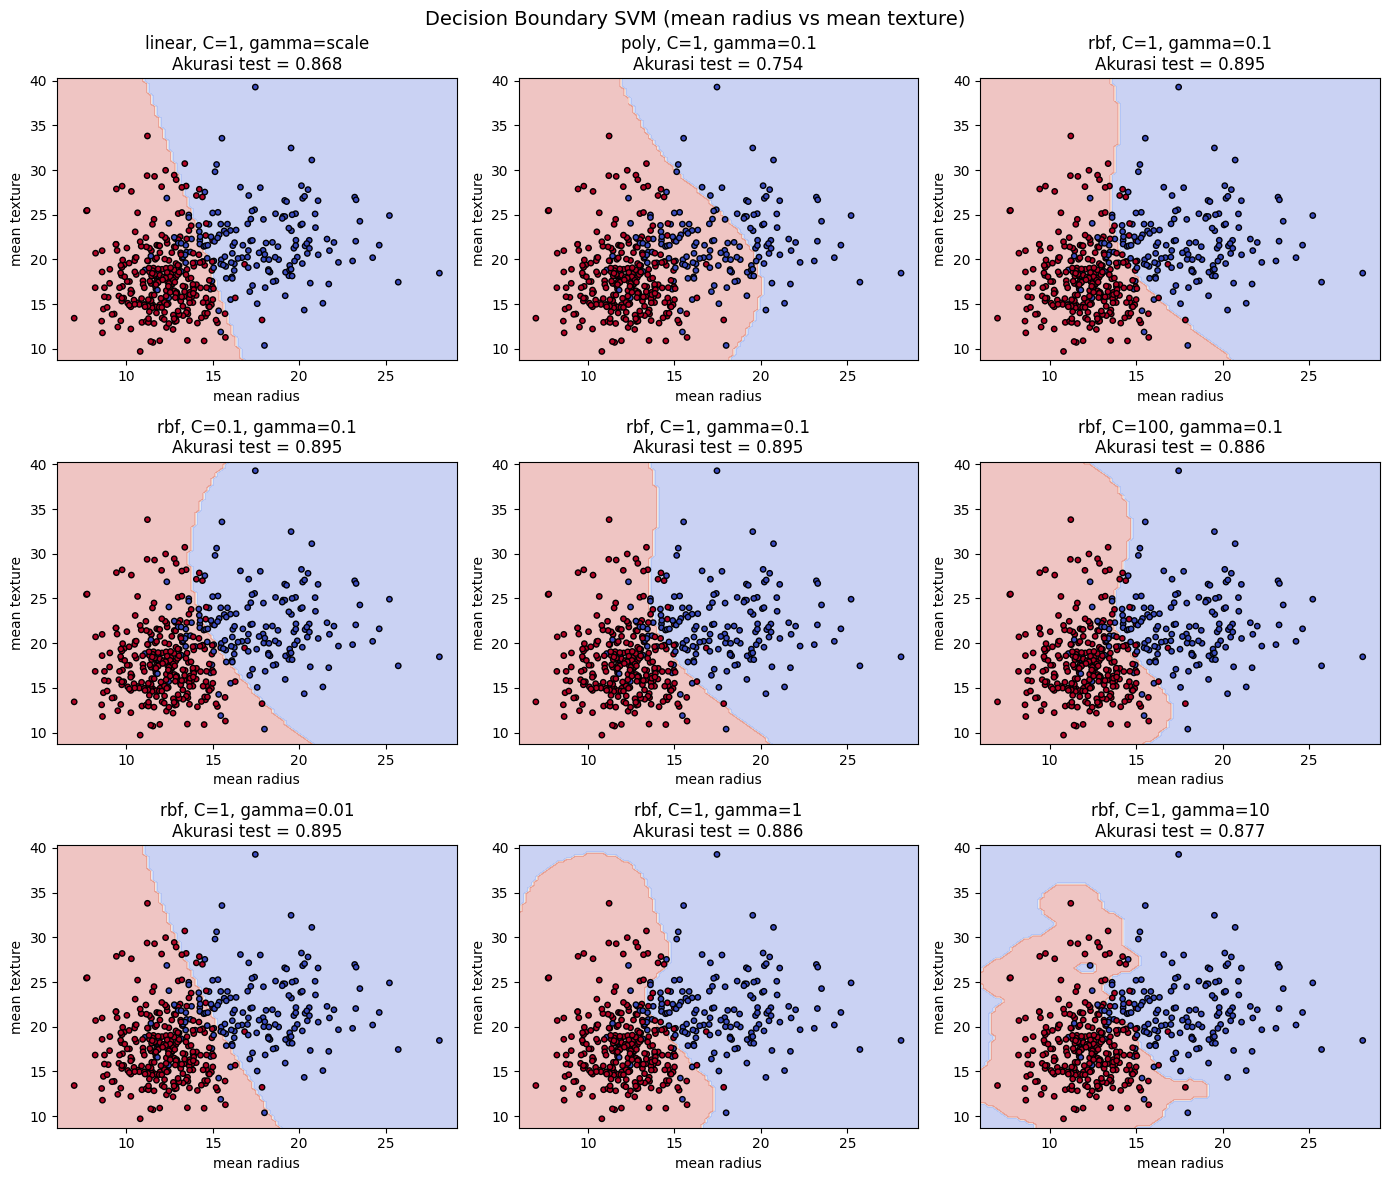

In [ ]:
fitur = ["mean radius", "mean texture"]
X2 = data.data[fitur]
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y,
    test_size=0.2, random_state=42, stratify=y)

# (kernel, C, gamma) - baris 1: beda kernel, baris 2: beda C,
# baris 3: beda gamma
konfigurasi = [
    ("linear", 1, "scale"), ("poly", 1, 0.1), ("rbf", 1, 0.1),
    ("rbf", 0.1, 0.1), ("rbf", 1, 0.1), ("rbf", 100, 0.1),
    ("rbf", 1, 0.01), ("rbf", 1, 1), ("rbf", 1, 10),
]

fig, axes = plt.subplots(3, 3, figsize=(14, 12))
print("\n=== Praktikum 2: Decision Boundary (2 fitur) ===")
for ax, (kernel, C, gamma) in zip(axes.ravel(), konfigurasi):
    model = Pipeline([("scaler", StandardScaler()),
                      ("svm", SVC(kernel=kernel, C=C, gamma=gamma))])
    model.fit(X2_train, y2_train)
    acc = accuracy_score(y2_test, model.predict(X2_test))
    DecisionBoundaryDisplay.from_estimator(
        model, X2_train, response_method="predict", cmap="coolwarm",
        alpha=0.3, ax=ax, xlabel=fitur[0], ylabel=fitur[1])
    ax.scatter(X2_train.iloc[:, 0], X2_train.iloc[:, 1], c=y2_train,
               cmap="coolwarm", edgecolor="k", s=15)
    ax.set_title(f"{kernel}, C={C}, gamma={gamma}\nAkurasi test = {acc:.3f}")
    print(f"kernel={kernel:<7} C={C:<5} gamma={gamma:<6} akurasi={acc:.3f}")
plt.suptitle("Decision Boundary SVM (mean radius vs mean texture)",
             fontsize=14)
plt.tight_layout()
plt.savefig("decision_boundary_svm.png", dpi=110)
plt.show()

8.7 Praktikum

In [ ]:
for kernel in ["linear", "poly", "rbf"]:
    model = Pipeline([("scaler", StandardScaler()), ("svm",
        SVC(kernel=kernel))])
    model.fit(X_train, y_train)
    acc = accuracy_score(y_test, model.predict(X_test))
    print(f"Kernel {kernel}: akurasi = {acc:.3f}")

Kernel linear: akurasi = 0.974
Kernel poly: akurasi = 0.912
Kernel rbf: akurasi = 0.982
